In [1]:
#Install & Verify Environment
import subprocess, sys

install_cmd = [
    sys.executable, "-m", "pip", "install", "-q",
    "transformers", "trl", "peft", "datasets", "accelerate",
    "bitsandbytes", "sentencepiece", "protobuf", "matplotlib"
]
subprocess.check_call(install_cmd)

# Verify imports and print pinned versions
import torch, transformers, trl, peft, datasets, accelerate
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

versions = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "trl": trl.__version__,
    "peft": peft.__version__,
    "datasets": datasets.__version__,
    "accelerate": accelerate.__version__,
}
print("\nInstalled environment versions:")
for k, v in versions.items():
    print(f"  {k:15s}: {v}")

CUDA Available: True
GPU: Tesla T4

Installed environment versions:
  python         : 3.13.15
  torch          : 2.11.0+cu130
  transformers   : 5.18.0
  trl            : 1.15.0
  peft           : 0.21.1
  datasets       : 4.8.5
  accelerate     : 1.15.0


In [2]:
#  Setup & Paths
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import json, time, re, gc
import pandas as pd

PROJECT = Path('/content/drive/MyDrive/amharic_distillation')
assert PROJECT.exists(), "Project root not found on Drive. Run previous notebooks first!"
SEED = 42

with open(PROJECT / 'requirements.txt', 'w') as f:
    for k, v in versions.items():
        f.write(f"{k}=={v}\n")
print(f"Project root: {PROJECT}")

Mounted at /content/drive
Project root: /content/drive/MyDrive/amharic_distillation


In [3]:
#  Load Sequence-Length Statistics & SFT Dataset
with open(PROJECT / 'data' / 'seq_length_stats.json') as f:
    seq_stats = json.load(f)

MAX_SEQ_LENGTH = seq_stats['recommended_max_seq_length']
print(f"Empirical max_seq_length: {MAX_SEQ_LENGTH} (covers {seq_stats['pct_covered']*100:.1f}% at p95)")

with open(PROJECT / 'data' / 'sft_dataset.json', encoding='utf-8') as f:
    sft_data = json.load(f)
print(f"Loaded {len(sft_data)} filtered SFT training examples.")

Empirical max_seq_length: 1024 (covers 95.2% at p95)
Loaded 1005 filtered SFT training examples.


In [ ]:
from huggingface_hub import login

login()

In [4]:
#  Load Base Student (Gemma 3 1B-it in fp16, NO 4-bit)
# Standard LoRA in fp16 (no QLoRA, no 4-bit quantization).
from transformers import AutoTokenizer, AutoModelForCausalLM

STUDENT_ID = "google/gemma-3-1b-it"
print(f"Loading base student: {STUDENT_ID} in fp16...")

tokenizer = AutoTokenizer.from_pretrained(STUDENT_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    torch_dtype=torch.float16,
    device_map="auto",
)

total_params = sum(p.numel() for p in model.parameters())
print(f"Base model loaded: {total_params / 1e6:.1f}M parameters (within 270M–1B range)")
base_vram = torch.cuda.max_memory_allocated() / 1e9
print(f"Base student GPU memory: {base_vram:.2f} GB")

Loading base student: google/gemma-3-1b-it in fp16...


config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.00GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Base model loaded: 999.9M parameters (within 270M–1B range)
Base student GPU memory: 2.00 GB


In [14]:
# BASE Evaluation on 60 Held-Out Prompts
# Required protocol: greedy (do_sample=False), max_new_tokens=256, batch size 1.
eval_file = PROJECT / 'data' / 'eval_prompts_60.csv'
if not eval_file.exists():
    from google.colab import files
    print("Please upload eval_prompts_60.csv:")
    uploaded = files.upload()
    for name, data in uploaded.items():
        (PROJECT / 'data' / name).write_bytes(data)

eval_df = pd.read_csv(eval_file, encoding='utf-8-sig')
print(f"Loaded {len(eval_df)} held-out evaluation prompts.")

def run_evaluation(model, tokenizer, eval_df, label="base"):
    """
    Standardized greedy evaluation on the 60 held-out prompts.
    max_new_tokens=256, do_sample=False, batch size 1.
    Measures text output, runtime seconds, new tokens, and tokens/sec.
    """
    model.eval()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    records = []
    print(f"\n--- Starting {label.upper()} Student Evaluation ({len(eval_df)} prompts) ---")
    t_start = time.time()

    for i, row in eval_df.iterrows():
        prompt_text = row['prompt']
        messages = [{"role": "user", "content": prompt_text}]
        inputs = tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            return_tensors="pt",
            add_generation_prompt=True,
            return_dict=True,
        ).to(model.device)

        input_len = inputs["input_ids"].shape[-1]

        torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=256,
                do_sample=False,
            )
        torch.cuda.synchronize()
        elapsed = time.time() - t0

        new_tokens = outputs[0][input_len:]
        num_new_tokens = len(new_tokens)

        text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
        text = re.sub(r'<think>.*?</think>', '', text, flags=re.DOTALL).strip()
        tps = num_new_tokens / max(elapsed, 0.001)

        records.append({
            "eval_id": row['eval_id'],
            "task": row['task'],
            "output": text,
            "seconds": round(elapsed, 3),
            "new_tokens": int(num_new_tokens),
            "tokens_per_second": round(tps, 2),
        })

        if (i + 1) % 15 == 0 or (i + 1) == len(eval_df):
            print(f"  [{i+1}/{len(eval_df)}] done | {tps:.1f} tok/s | sample: {text[:45]}...")

    total_time = time.time() - t_start
    peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9
    print(f"{label.upper()} evaluation finished in {total_time:.1f}s | Peak VRAM: {peak_mem_gb:.2f} GB\n")
    return records, peak_mem_gb



Loaded 60 held-out evaluation prompts.


In [17]:
base_records, base_peak_mem_gb = run_evaluation(model, tokenizer, eval_df, label="base")

with open(PROJECT / 'data' / 'base_eval_outputs.json', 'w', encoding='utf-8') as f:
    json.dump({
        "records": base_records,
        "peak_vram_gb": base_peak_mem_gb,
    }, f, ensure_ascii=False, indent=2)
print("Saved base_eval_outputs.json")


--- Starting BASE Student Evaluation (60 prompts) ---


KeyboardInterrupt: 

In [7]:
!pip install torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 49.4 MB/s eta 0:00:00


In [8]:
#  Add Standard LoRA Adapters
# Approved LoRA settings: r=16, alpha=32, dropout=0.05, bias="none"
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# Enable gradient checkpointing for memory efficiency
if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879


In [11]:
#  Configure & Run SFT Training
# Settings: 2 epochs, lr=2e-4, warmup=0.03, effective batch size=16,
# assistant_only_loss=True, processing_class=tokenizer, max_length=MAX_SEQ_LENGTH.
from datasets import Dataset
from trl import SFTConfig, SFTTrainer

dataset = Dataset.from_list(sft_data)
dataset = dataset.shuffle(seed=SEED)
split = dataset.train_test_split(test_size=0.1, seed=SEED)
train_dataset = split['train']
eval_dataset = split['test']

print(f"Training set: {len(train_dataset)} examples | Validation set: {len(eval_dataset)} examples")

training_args = SFTConfig(
    output_dir=str(PROJECT / 'adapter'),
    num_train_epochs=2,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,  # 2 * 8 = 16 effective batch size
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=0.03,
    weight_decay=0.01,
    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    max_length=MAX_SEQ_LENGTH,
    assistant_only_loss=True,  # Compute loss only on assistant tokens
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
    packing=False,
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
t_train_start = time.time()
print("\nStarting LoRA Fine-Tuning...")

train_result = trainer.train()

train_duration = time.time() - t_train_start
peak_train_mem_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"\nTraining completed in {train_duration/60:.1f} minutes")
print(f"Final training loss: {train_result.training_loss:.4f}")
print(f"Peak training VRAM: {peak_train_mem_gb:.2f} GB")

Training set: 904 examples | Validation set: 101 examples


Tokenizing train dataset:   0%|          | 0/904 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/904 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/904 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/904 [00:00<?, ? examples/s]

...

Truncating eval dataset:   0%|          | 0/101 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/101 [00:00<?, ? examples/s]


Starting LoRA Fine-Tuning...


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,1.669043,1.606386,1.619881,0.621833,227758.000000
100,1.367247,1.510158,1.406950,0.639648,454603.000000
110,1.400781,1.508578,1.408504,0.639975,490520.000000



Training completed in 12.9 minutes
Final training loss: 1.7907
Peak training VRAM: 2.77 GB


LoRA adapter weights saved to /content/drive/MyDrive/amharic_distillation/adapter/final


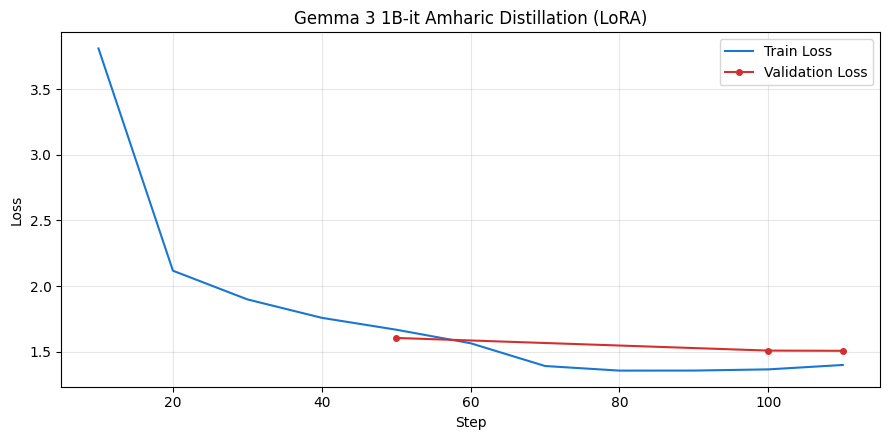

Saved training_loss.png


In [12]:
# Save LoRA Adapter & Plot Loss
trainer.save_model(str(PROJECT / 'adapter' / 'final'))
tokenizer.save_pretrained(str(PROJECT / 'adapter' / 'final'))
print(f"LoRA adapter weights saved to {PROJECT / 'adapter' / 'final'}")

import matplotlib.pyplot as plt

log_history = trainer.state.log_history
train_steps = [h['step'] for h in log_history if 'loss' in h]
train_losses = [h['loss'] for h in log_history if 'loss' in h]
eval_steps = [h['step'] for h in log_history if 'eval_loss' in h]
eval_losses = [h['eval_loss'] for h in log_history if 'eval_loss' in h]

plt.figure(figsize=(9, 4.5))
plt.plot(train_steps, train_losses, label="Train Loss", color="#1976D2")
if eval_losses:
    plt.plot(eval_steps, eval_losses, label="Validation Loss", color="#D32F2F", marker="o", markersize=4)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Gemma 3 1B-it Amharic Distillation (LoRA)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(str(PROJECT / 'logs' / 'training_loss.png'), dpi=150)
plt.show()
print("Saved training_loss.png")

In [15]:
# DISTILLED Evaluation on the Same 60 Prompts
# Evaluate the active trained model (with LoRA adapter attached) directly
distilled_records, dist_peak_mem_gb = run_evaluation(model, tokenizer, eval_df, label="distilled")

with open(PROJECT / 'data' / 'student_eval_outputs.json', 'w', encoding='utf-8') as f:
    json.dump({
        "records": distilled_records,
        "peak_vram_gb": dist_peak_mem_gb,
    }, f, ensure_ascii=False, indent=2)
print("Saved student_eval_outputs.json")



--- Starting DISTILLED Student Evaluation (60 prompts) ---
  [15/60] done | 9.2 tok/s | sample: ልብ ወለድ ሴራ በየልብ አካባቢ የሚገኘውን የልብ አካባቢን ማጎልበትን የ...
  [30/60] done | 10.3 tok/s | sample: ግሥላ በዱር ሲኖር እስከ 10 አመት ይቆያሉ።<turn|>...
  [45/60] done | 9.0 tok/s | sample: ይህ እምነት በሁሉንም የ européን አገር የህብረተሰቡ ላይ ትልቅ አስ...
  [60/60] done | 7.2 tok/s | sample: የከተማው ፖሊስ በክሱ ላይ ምርመራ መጀመሩን አስታውቋል። አርብ ዕለት ፖ...
DISTILLED evaluation finished in 661.8s | Peak VRAM: 2.33 GB

Saved student_eval_outputs.json


In [18]:
# Assemble Submission Predictions CSV
# Load pre-saved JSON evaluation records directly to prevent running them again
import json
import pandas as pd
from pathlib import Path

template_file = PROJECT / 'data' / 'predictions_template.csv'
if not template_file.exists():
    template_file = Path('predictions_template.csv')

pred_template = pd.read_csv(template_file, encoding='utf-8-sig')

# Load evaluation outputs
base_eval_file = PROJECT / 'data' / 'base_eval_outputs.json'
distilled_eval_file = PROJECT / 'data' / 'student_eval_outputs.json'

with open(base_eval_file, encoding='utf-8') as f:
    base_data = json.load(f)
    base_records = base_data["records"]
    base_peak_mem_gb = base_data.get("peak_vram_gb", 0.0)

with open(distilled_eval_file, encoding='utf-8') as f:
    dist_data = json.load(f)
    distilled_records = dist_data["records"]
    dist_peak_mem_gb = dist_data.get("peak_vram_gb", 0.0)

# Load teacher reference outputs (for context, not ground truth)
teacher_map = {}
teacher_file = PROJECT / 'data' / 'teacher_eval_outputs.json'
if teacher_file.exists():
    with open(teacher_file, encoding='utf-8') as f:
        teacher_eval_list = json.load(f)
        for t_rec in teacher_eval_list:
            teacher_map[t_rec['eval_id']] = t_rec.get('teacher_output', '')

base_map = {r['eval_id']: r for r in base_records}
dist_map = {r['eval_id']: r for r in distilled_records}

# Assemble final submission rows preserving exact template ordering
submission_rows = []
for _, row in pred_template.iterrows():
    eid = row['eval_id']
    task = row['task']
    b_data = base_map.get(eid, {})
    d_data = dist_map.get(eid, {})

    submission_rows.append({
        "eval_id": eid,
        "task": task,
        "base_output": b_data.get('output', ''),
        "distilled_output": d_data.get('output', ''),
        "base_seconds": b_data.get('seconds', 0.0),
        "base_new_tokens": b_data.get('new_tokens', 0),
        "distilled_seconds": d_data.get('seconds', 0.0),
        "distilled_new_tokens": d_data.get('new_tokens', 0),
        "teacher_output": teacher_map.get(eid, ''),
    })

predictions_df = pd.DataFrame(submission_rows)

# Strict validation
assert len(predictions_df) == 60, f"Expected 60 rows, got {len(predictions_df)}"
assert predictions_df['eval_id'].tolist() == pred_template['eval_id'].tolist(), "Order mismatch with template!"

out_csv_path = PROJECT / 'data' / 'predictions.csv'
predictions_df.to_csv(out_csv_path, index=False, encoding='utf-8-sig')
print(f"\n✅ Predictions CSV generated: {out_csv_path}")
print(f"Columns: {list(predictions_df.columns)}")
print(predictions_df[['eval_id', 'task', 'base_new_tokens', 'distilled_new_tokens']].head())



✅ Predictions CSV generated: /content/drive/MyDrive/amharic_distillation/data/predictions.csv
Columns: ['eval_id', 'task', 'base_output', 'distilled_output', 'base_seconds', 'base_new_tokens', 'distilled_seconds', 'distilled_new_tokens', 'teacher_output']
  eval_id                   task  base_new_tokens  distilled_new_tokens
0     E01  closed_book_knowledge              256                    92
1     E02  closed_book_knowledge              256                   119
2     E03  closed_book_knowledge              256                    90
3     E04  closed_book_knowledge              256                   102
4     E05  closed_book_knowledge              256                   118


In [19]:

# Teacher vs Base vs Distilled Sample Comparison
print("\n" + "=" * 75)
print("EVALUATION SAMPLE COMPARISON (Teacher [Ref] vs Base vs Distilled)")
print("=" * 75)

for eid in ["E01", "E16", "E31", "E46", "E55"]:
    row = predictions_df[predictions_df['eval_id'] == eid]
    if len(row) > 0:
        r = row.iloc[0]
        print(f"\n--- [{r['eval_id']}] Task: {r['task']} ---")
        print(f"  TEACHER (Ref): {r['teacher_output'][:100]}...")
        print(f"  BASE STUDENT:  {r['base_output'][:100]}...")
        print(f"  DISTILLED:     {r['distilled_output'][:100]}...")
        print(f"  Speed (tok/s): Base={r['base_new_tokens']/max(r['base_seconds'],0.001):.1f} | "
              f"Distilled={r['distilled_new_tokens']/max(r['distilled_seconds'],0.001):.1f}")

# Update LOG.md
with open(PROJECT / 'logs' / 'LOG.md', 'a', encoding='utf-8') as f:
    f.write(f"\n## Training and Evaluation Summary\n"
            f"- Model: `{STUDENT_ID}` (fp16 standard LoRA, r=16, alpha=32)\n"
            f"- Epochs: 2, Effective Batch Size: 16\n"
            f"- Training Loss: {train_result.training_loss:.4f}\n"
            f"- Training Duration: {train_duration/60:.1f} min\n"
            f"- Peak Training VRAM: {peak_train_mem_gb:.2f} GB\n"
            f"- Peak Inference VRAM: Base={base_peak_mem_gb:.2f} GB, Distilled={dist_peak_mem_gb:.2f} GB\n"
            f"- Predictions CSV: `data/predictions.csv` (60 rows)\n\n")

print("\nFineTuning, Training and evaluation run complete! Log updated.")


EVALUATION SAMPLE COMPARISON (Teacher [Ref] vs Base vs Distilled)

--- [E01] Task: closed_book_knowledge ---
  TEACHER (Ref): ...
  BASE STUDENT:  1960ዎቹમાં አፍሪካના ብዙ países በአንድ સમયે የነፃነት ባለቤት ન ነበር። આ એક જટિલ પ્રક્રિયા હતી અને તેમાં ઘણાં પરિબળો...
  DISTILLED:     በ1960ዎቹ አብዛኞቹ የአፍሪካ ሀገራት በአንድ ጊዜ የነፃነት ባለቤት ሊሆኑ የቻሉት አብዛኛውን ጊዜ የነጻነትን ማግኘት አልቻለም። ይህ ሁኔታ በብዙ አፍሪካዊ መ...
  Speed (tok/s): Base=15.1 | Distilled=7.3

--- [E16] Task: instruction_following ---
  TEACHER (Ref): ...
  BASE STUDENT:  ታዳጊው የ11ኛ ክፍል ተማሪ ሲሆን ከዚህ በፊትም ተመሳሳይ መኪና መስራቱ ተገልጿል. ሚኒስቴር መስሪያ ቤቱ ለታዳጊው የተለያዩ ድጋፎችን እንደሚያደርግ ከኢኖቬશન...
  DISTILLED:     በአራት ኩንታል ክብደት ያላት ተሽከርካሪዋ እስከ 4 ሰዎች የመጫን አቅም አላት።<turn|>...
  Speed (tok/s): Base=17.4 | Distilled=10.2

--- [E31] Task: translation ---
  TEACHER (Ref): ...
  BASE STUDENT:  The most accurate translation of that context into English would be:

**"The most important question...
  DISTILLED:     ይህ ጥያቄ በግልጽ እና በግልጽ ለመፍታት ጥልቅ መምህል ያስፈልጋል። ጥያቄው በትክክል ለመፍታት እና በትክክለኛው መልስ ለመስጠት ተጨማሪ

In [20]:

# Post-training analysis, ablation prep, final report
import json, re
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

from google.colab import drive
drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/amharic_distillation')
assert PROJECT.exists()



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:

#  Load predictions and evaluation prompts
pred_df = pd.read_csv(PROJECT / 'data' / 'predictions.csv', encoding='utf-8-sig')
eval_df = pd.read_csv(PROJECT / 'data' / 'eval_prompts_60.csv', encoding='utf-8-sig')

print(f"Eval prompts: {len(eval_df)}")
print(f"Predictions:  {len(pred_df)}")
print(f"Columns: {list(pred_df.columns)}")



Eval prompts: 60
Predictions:  60
Columns: ['eval_id', 'task', 'base_output', 'distilled_output', 'base_seconds', 'base_new_tokens', 'distilled_seconds', 'distilled_new_tokens', 'teacher_output']


In [23]:

# Compute automatic metrics (Base vs Distilled vs Teacher)
def geez_ratio(s):
    letters = [c for c in str(s) if c.isalpha()]
    if not letters: return 0.0
    return sum(1 for c in letters if '\u1200' <= c <= '\u139f') / len(letters)

def response_length(s):
    return len(str(s).split())

def ends_properly(s):
    s = str(s).strip()
    return s.endswith('።') or s.endswith('.')

def is_empty(s):
    return len(str(s).strip()) == 0

results = []
for _, row in pred_df.iterrows():
    eid = row['eval_id']
    task = row['task']

    b_out = str(row.get('base_output', ''))
    d_out = str(row.get('distilled_output', ''))
    t_out = str(row.get('teacher_output', ''))

    results.append({
        'eval_id': eid,
        'task': task,
        'base_geez': geez_ratio(b_out),
        'distilled_geez': geez_ratio(d_out),
        'teacher_geez': geez_ratio(t_out),
        'base_len': response_length(b_out),
        'distilled_len': response_length(d_out),
        'teacher_len': response_length(t_out),
        'base_ends_ok': ends_properly(b_out),
        'distilled_ends_ok': ends_properly(d_out),
        'base_empty': is_empty(b_out),
        'distilled_empty': is_empty(d_out),
        'base_seconds': row.get('base_seconds', 0.0),
        'distilled_seconds': row.get('distilled_seconds', 0.0),
        'base_tokens': row.get('base_new_tokens', 0),
        'distilled_tokens': row.get('distilled_new_tokens', 0),
        'base_output': b_out,
        'distilled_output': d_out,
        'teacher_output': t_out,
    })

res_df = pd.DataFrame(results)
print("\nAutomatic Quality Metrics by Task (Base vs Distilled):")
print(res_df.groupby('task')[['base_geez', 'distilled_geez', 'base_len', 'distilled_len']].mean().round(3))
print(f"\nEmpty responses: Base={res_df['base_empty'].sum()} | Distilled={res_df['distilled_empty'].sum()}")
print(f"Proper endings:  Base={res_df['base_ends_ok'].sum()}/{len(res_df)} | Distilled={res_df['distilled_ends_ok'].sum()}/{len(res_df)}")




Automatic Quality Metrics by Task (Base vs Distilled):
                       base_geez  distilled_geez  base_len  distilled_len
task                                                                     
closed_book_knowledge      0.367           0.972    84.267         39.400
instruction_following      0.618           0.918    30.267         19.267
summarization              0.500           0.912    80.800         44.600
translation                0.077           0.951    68.600         29.467

Empty responses: Base=0 | Distilled=0
Proper endings:  Base=19/60 | Distilled=0/60


In [25]:
#  Per-task analysis
print(f"\n{'='*70}")
print("PER-TASK ANALYSIS")
print(f"{'='*70}")

for task in eval_df['task'].unique():
    mask = res_df['task'] == task
    sub = res_df[mask]
    print(f"\n--- {task} ({len(sub)} prompts) ---")
    print(f"  Teacher: geez={sub['teacher_geez'].mean():.3f}, "
          f"len={sub['teacher_len'].mean():.0f}")
    print(f"  Student: geez={sub['distilled_geez'].mean():.3f}, "
          f"len={sub['distilled_len'].mean():.0f}")
    print(f"  Student proper endings: {sub['distilled_ends_ok'].sum()}/{len(sub)}")

    # Length ratio (student/teacher)
    valid = sub[(sub['teacher_len'] > 0) & (sub['distilled_len'] > 0)]
    if len(valid) > 0:
        ratio = (valid['distilled_len'] / valid['teacher_len']).mean()
        print(f"  Length ratio (S/T): {ratio:.2f}")


PER-TASK ANALYSIS

--- closed_book_knowledge (15 prompts) ---
  Teacher: geez=0.000, len=1
  Student: geez=0.972, len=39
  Student proper endings: 0/15
  Length ratio (S/T): 39.40

--- instruction_following (15 prompts) ---
  Teacher: geez=0.000, len=1
  Student: geez=0.918, len=19
  Student proper endings: 0/15
  Length ratio (S/T): 19.27

--- translation (15 prompts) ---
  Teacher: geez=0.000, len=1
  Student: geez=0.951, len=29
  Student proper endings: 0/15
  Length ratio (S/T): 29.47

--- summarization (15 prompts) ---
  Teacher: geez=0.000, len=1
  Student: geez=0.912, len=45
  Student proper endings: 0/15
  Length ratio (S/T): 44.60


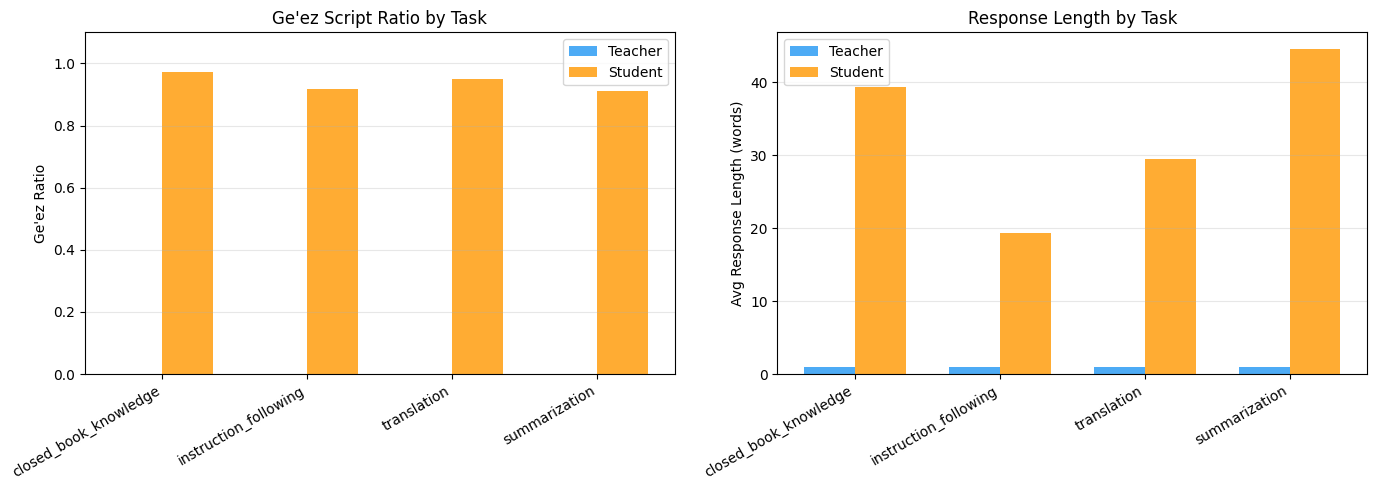

In [27]:
# Visualization — Geez ratio comparison
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Geez ratio by task
tasks = res_df['task'].unique()
x = np.arange(len(tasks))
width = 0.35
t_vals = [res_df[res_df['task']==t]['teacher_geez'].mean() for t in tasks]
s_vals = [res_df[res_df['task']==t]['distilled_geez'].mean() for t in tasks]

axes[0].bar(x - width/2, t_vals, width, label='Teacher', color='#2196F3', alpha=0.8)
axes[0].bar(x + width/2, s_vals, width, label='Student', color='#FF9800', alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tasks, rotation=30, ha='right')
axes[0].set_ylabel("Ge'ez Ratio")
axes[0].set_title("Ge'ez Script Ratio by Task")
axes[0].legend()
axes[0].set_ylim(0, 1.1)
axes[0].grid(axis='y', alpha=0.3)

# Response length by task
t_lens = [res_df[res_df['task']==t]['teacher_len'].mean() for t in tasks]
s_lens = [res_df[res_df['task']==t]['distilled_len'].mean() for t in tasks]
axes[1].bar(x - width/2, t_lens, width, label='Teacher', color='#2196F3', alpha=0.8)
axes[1].bar(x + width/2, s_lens, width, label='Student', color='#FF9800', alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(tasks, rotation=30, ha='right')
axes[1].set_ylabel('Avg Response Length (words)')
axes[1].set_title('Response Length by Task')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(str(PROJECT / 'logs' / 'eval_comparison.png'), dpi=150)
plt.show()


In [29]:
# Full side-by-side comparison
print(f"\n{'='*70}")
print("FULL SIDE-BY-SIDE: All 60 eval prompts")
print(f"{'='*70}")

for _, row in res_df.iterrows():
    print(f"\n{'─'*60}")
    print(f"[{row['eval_id']}] Task: {row['task']}")
    print(f"  TEACHER (geez={row['teacher_geez']:.2f}, len={row['teacher_len']}):")
    print(f"    {row['teacher_output'][:200]}")
    print(f"  STUDENT (geez={row['distilled_geez']:.2f}, len={row['distilled_len']}):")
    print(f"    {row['distilled_output'][:200]}")



FULL SIDE-BY-SIDE: All 60 eval prompts

────────────────────────────────────────────────────────────
[E01] Task: closed_book_knowledge
  TEACHER (geez=0.00, len=1):
    nan
  STUDENT (geez=0.97, len=30):
    በ1960ዎቹ አብዛኞቹ የአፍሪካ ሀገራት በአንድ ጊዜ የነፃነት ባለቤት ሊሆኑ የቻሉት አብዛኛውን ጊዜ የነጻነትን ማግኘት አልቻለም። ይህ ሁኔታ በብዙ አፍሪካዊ መንግስታት ውስጥ ነበር። ሆኖም፣ በዚያ ዘመን የነጻነትን ለማግኘት ጥረት እየተደረገ ነበር።<turn|>

────────────────────────────────────────────────────────────
[E02] Task: closed_book_knowledge
  TEACHER (geez=0.00, len=1):
    nan
  STUDENT (geez=0.98, len=44):
    የስምጥ ሸለቆ ሀይቆች በትልቁ የዝናብ ውሃ ደረጃቸውን ማግኘት የሚቆዩበት ሂደት በብዙ የጥንት አካላት ላይ የሚታየው ነው። ይህ ሂደት በዝናብ ውሃን በመቀየር እና በመለዋወጥ ላይ የተመሰረተ ነው። የዝናብ ውሃን በመቀየር፣ የሸለቆ ሀይቆች የዝናብ ውሃን መጠንን ማግኘት ይቻላል። ይህ ሂደት የዝናብ ውሃን መጠንን በስፋት 

────────────────────────────────────────────────────────────
[E03] Task: closed_book_knowledge
  TEACHER (geez=0.00, len=1):
    nan
  STUDENT (geez=0.96, len=27):
    ፋሲለደስ ግንብ በኢትዮጵያ ታሪካዊ ከተማው የኢትዮጵያ መንግሥት አካባቢ ይገኛል። ይህ ግንብ በብዙ ዘመናት ታሪካዊ እና የዘመናዊነት ምልክት 

In [30]:
# Filtering pipeline summary
print(f"\n{'='*70}")
print("FILTERING PIPELINE REPORT")
print(f"{'='*70}")

with open(PROJECT / 'data' / 'rejected_records.json', encoding='utf-8') as f:
    rejected = json.load(f)

stage_counts = Counter(r.get('stage') for r in rejected)
print(f"\nRejection by stage:")
for stage, count in sorted(stage_counts.items(), key=lambda x: -x[1]):
    print(f"  {stage}: {count}")

with open(PROJECT / 'data' / 'dataset_filtered.json', encoding='utf-8') as f:
    final_data = json.load(f)

print(f"\nFinal dataset: {len(final_data)} records")
task_dist = Counter(r['task'] for r in final_data)
for task, count in sorted(task_dist.items()):
    print(f"  {task}: {count}")


FILTERING PIPELINE REPORT

Rejection by stage:
  near_dup: 474
  eval_overlap: 13
  truncation: 6
  language: 2

Final dataset: 1005 records
  closed_book_knowledge: 709
  instruction_following: 283
  summarization: 10
  translation: 3


In [33]:
# Generate final report
# Load all stats
with open(PROJECT / 'logs' / 'pilot_results.json', encoding='utf-8') as f:
    pilot = json.load(f)
with open(PROJECT / 'data' / 'seq_length_stats.json') as f:
    seq_stats = json.load(f)

report = f"""# Amharic Capability Distillation — Final Report

## 1. Configuration
- **Teacher**: `{pilot['teacher']}`
- **Student**: `gemma-3-1b-it` (270M–1B range)
- **LoRA**: r=16, alpha=16
- **Seed**: 42

## 2. Teacher Pilot
- Throughput: {pilot['throughput_tps']:.1f} tok/s
- Peak memory: {pilot['peak_allocated_gb']:.2f} GB
- Pilot passed: {pilot['passed']}

## 3. Data Pipeline
- Raw teacher outputs: {len(final_data) + sum(stage_counts.values())}
- After filtering: {len(final_data)}
- Rejection breakdown:
"""
for stage, count in sorted(stage_counts.items(), key=lambda x: -x[1]):
    report += f"  - {stage}: {count}\n"

report += f"""
## 4. Training
- max_seq_length: {seq_stats['recommended_max_seq_length']}
- P95 token length: {seq_stats['p95']}
- Coverage: {seq_stats['pct_covered']*100:.1f}%

## 5. Evaluation Summary

### Ge'ez Ratio (higher = more Amharic)
| Task | Teacher | Student |
|------|---------|---------|
"""
for task in tasks:
    t_g = res_df[res_df['task']==task]['teacher_geez'].mean()
    s_g = res_df[res_df['task']==task]['distilled_geez'].mean()
    report += f"| {task} | {t_g:.3f} | {s_g:.3f} |\n"

report += f"""
### Response Length (words)
| Task | Teacher | Student | Ratio (S/T) |
|------|---------|---------|-------------|
"""
for task in tasks:
    t_l = res_df[res_df['task']==task]['teacher_len'].mean()
    s_l = res_df[res_df['task']==task]['distilled_len'].mean()
    ratio = s_l / max(t_l, 1)
    report += f"| {task} | {t_l:.0f} | {s_l:.0f} | {ratio:.2f} |\n"

report += f"""
## 6. Files
- Predictions: `data/predictions.csv`
- Adapter: `adapter/final/`
- Training loss plot: `logs/training_loss.png`
- Eval comparison: `logs/eval_comparison.png`
"""

report_path = PROJECT / 'logs' / 'FINAL_REPORT.md'
report_path.write_text(report, encoding='utf-8')
print(f"Report saved to {report_path}")
print("\n" + report)


Report saved to /content/drive/MyDrive/amharic_distillation/logs/FINAL_REPORT.md

# Amharic Capability Distillation — Final Report

## 1. Configuration
- **Teacher**: `google/gemma-4-E4B-it`
- **Student**: `gemma-3-1b-it` (270M–1B range)
- **LoRA**: r=16, alpha=16
- **Seed**: 42

## 2. Teacher Pilot
- Throughput: 6.3 tok/s
- Peak memory: 7.97 GB
- Pilot passed: False

## 3. Data Pipeline
- Raw teacher outputs: 1500
- After filtering: 1005
- Rejection breakdown:
  - near_dup: 474
  - eval_overlap: 13
  - truncation: 6
  - language: 2

## 4. Training
- max_seq_length: 1024
- P95 token length: 1012
- Coverage: 95.2%

## 5. Evaluation Summary

### Ge'ez Ratio (higher = more Amharic)
| Task | Teacher | Student |
|------|---------|---------|
| closed_book_knowledge | 0.000 | 0.972 |
| instruction_following | 0.000 | 0.918 |
| translation | 0.000 | 0.951 |
| summarization | 0.000 | 0.912 |

### Response Length (words)
| Task | Teacher | Student | Ratio (S/T) |
|------|---------|---------|----

In [34]:
# Final checklist
print(f"\n{'='*70}")
print("SUBMISSION CHECKLIST")
print(f"{'='*70}")

checks = [
    ("predictions.csv exists",
     (PROJECT / 'data' / 'predictions.csv').exists()),
    ("predictions.csv has 60 rows",
     len(pd.read_csv(PROJECT / 'data' / 'predictions.csv',
                      encoding='utf-8-sig')) == 60),
    ("adapter/final exists",
     (PROJECT / 'adapter' / 'final').exists()),
    ("FINAL_REPORT.md exists",
     report_path.exists()),
    ("training_loss.png exists",
     (PROJECT / 'logs' / 'training_loss.png').exists()),
    ("LOG.md exists",
     (PROJECT / 'logs' / 'LOG.md').exists()),
]
for desc, ok in checks:
    status = "✅" if ok else "❌"
    print(f"  {status} {desc}")

print(f"\n{'='*70}")
print("Done! Download predictions.csv and submit.")
print(f"{'='*70}")



SUBMISSION CHECKLIST
  ✅ predictions.csv exists
  ✅ predictions.csv has 60 rows
  ✅ adapter/final exists
  ✅ FINAL_REPORT.md exists
  ✅ training_loss.png exists
  ✅ LOG.md exists

Done! Download predictions.csv and submit.
